In [2]:
pip install opencv-python numpy matplotlib keras mtcnn



   ---------------------------------------- 0.0/1.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.9 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.9 MB ? eta -:--:--
   ---------------- ----------------------- 0.8/1.9 MB 1.4 MB/s eta 0:00:01
   ---------------------- ----------------- 1.0/1.9 MB 1.6 MB/s eta 0:00:01
   --------------------------- ------------ 1.3/1.9 MB 1.5 MB/s eta 0:00:01
   --------------------------- ------------ 1.3/1.9 MB 1.5 MB/s eta 0:00:01
   ---------------------------------------- 1.9/1.9 MB 1.3 MB/s eta 0:00:00
  Attempting uninstall: lz4
    Found existing installation: lz4 4.3.2
    Uninstalling lz4-4.3.2:
      Successfully uninstalled lz4-4.3.2


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step


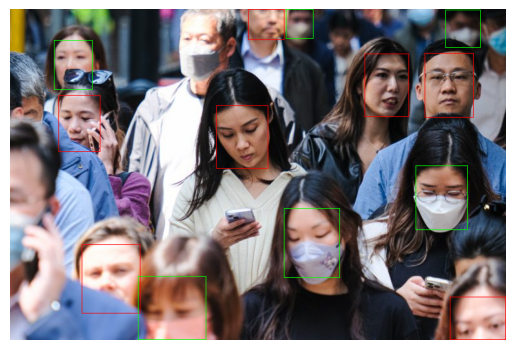

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from keras.models import load_model
from mtcnn import MTCNN

# Load pre-trained mask detection model
model = load_model("../face_mask_model.h5")

# Initialize MTCNN face detector
detector = MTCNN()

# Function to detect faces and classify mask usage
def detect_mask(image_path):
    # Load and convert image
    img = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Detect faces
    faces = detector.detect_faces(img_rgb)

    for face in faces:
        x, y, w, h = face["box"]

        # Extract face region
        face_crop = img_rgb[y:y+h, x:x+w]
        face_crop = cv2.resize(face_crop, (128, 128))
        face_crop = np.array(face_crop) / 255.0
        face_crop = np.expand_dims(face_crop, axis=0)

        # Predict mask usage
        prediction = model.predict(face_crop)
        has_mask = np.argmax(prediction) == 0  # Mask -> Green, No Mask -> Red

        # Choose box color
        color = (0, 255, 0) if has_mask else (255, 0, 0)

        # (thickness = 1)
        cv2.rectangle(img_rgb, (x, y), (x+w, y+h), color, 1)

    # Display the image with bounding boxes
    plt.imshow(img_rgb)
    plt.axis("off")
    plt.show()

# Test on an image
detect_mask("../dataset/test/sample_test_9.jpg")  # Change to your image path


In [ ]:
import cv2
import numpy as np
import tensorflow as tf
from keras.models import load_model
from mtcnn import MTCNN

# Load pre-trained mask detection model
model = load_model("../face_mask_model.h5")

# Initialize MTCNN face detector
detector = MTCNN()

# Start video capture
cap = cv2.VideoCapture(0)  # Use webcam

while True:
    ret, frame = cap.read()
    if not ret:
        break  # Exit if frame not captured

    img_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)  # Convert to RGB for MTCNN

    # Detect faces
    faces = detector.detect_faces(img_rgb)

    for face in faces:
        x, y, w, h = face["box"]

        # Extract face region
        face_crop = img_rgb[y:y + h, x:x + w]
        face_crop = cv2.resize(face_crop, (128, 128))
        face_crop = np.array(face_crop) / 255.0  # Normalize
        face_crop = np.expand_dims(face_crop, axis=0)

        # Predict mask usage
        prediction = model.predict(face_crop)
        print("Prediction:", prediction)  # Debugging output

        # Determine mask/no mask based on model output
        has_mask = np.argmax(prediction) == 0  # Adjust index if necessary

        # Choose box color (Green for Mask, Red for No Mask)
        color = (0, 255, 0) if has_mask else (0, 0, 255)

        
        cv2.rectangle(frame, (x, y), (x + w, y + h), color, 1)

    # Display the output
    cv2.imshow("Face Mask Detection", frame)

    #'q' to exit
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break


cap.release()
cv2.destroyAllWindows()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step
Prediction: [[0.01410319 0.98589677]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
Prediction: [[0.04022182 0.9597782 ]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
Prediction: [[0.00722087 0.9927791 ]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
Prediction: [[0.02342942 0.97657055]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
Prediction: [[0.65584964 0.3441504 ]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
Prediction: [[0.02629712 0.97370285]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
Prediction: [[0.01203128 0.9879687 ]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
Prediction: [[0.00534771 0.9946523 ]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
Prediction: [[0.02170732 0.97829264]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
Prediction: [[0.00788395 0.99211603]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
Prediction: [[0.02645353 0.9735465 ]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
Prediction: [[9.999299e-01 7.007368e-05]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
Prediction: [[9.9999738e-01 2.5962186e-06]]